# Sparse photographic reconstruction: what the samples can determine


<!-- inverse-evidence-audit:20261026:start -->

> **本次维护说明：** 以下导航依据当前观测文件、实际求解代码和保留的输出编写。本次仅完善叙述，不把历史图、缓存结果或未执行代码称作本次新计算；没有独立 GT 时，方法参考不代表真实准确性。

### 观测 → 物理目标：masked_texture_image_reconstruction

**观测 y：** observations(1, 240, 320)；mask(1, 240, 320)。具体单位以本Notebook数据表及README为准。

**恢复目标 x：** 完整照片编码亮度。

**GT/参考来源：** GT为生成观测之前定义的模拟物理目标；须与无噪声观测/拟合预测区分。

**由观测恢复目标：** 已知掩膜M抽样y=Mx。本地路径为 `solvers.reconstruct(TV/TGV原始对偶)`。现有Notebook包含主动调用路径；本次只读审核未重跑，保留的execution_count/图像只说明已有输出，不能声称本轮执行。

**现有实验与图：** 保留图像输出位于cell 8（cell编号按文件内从0计）。章节包括：# Sparse photographic reconstruction: what the samples can determine；## 2. Data；## 3. Physics；## 4. Method；## 5. Results；### Actual evidence and visual comparisons；## 6. Conclusion。应联合阅读观测图、完整恢复目标、参考差异与残差/敏感性实验；方法一致性不等于物理精度。

**限制：** GT是掩膜前完整真实照片；观测缺失由模拟掩膜产生。

<!-- inverse-evidence-audit:20261026:end -->


## 1. Problem

Recover a complete spatial luminance image from sparse author-provided photographic samples while preserving edges and smooth color transitions across missing pixels.

This notebook actively reconstructs the complete author photograph acquisition using local explicit TV/TGV mathematics. It does not load cached reconstructions as fresh results. Real photographic content is distinct from its author-defined simulated missing-pixel measurement. The fixed mask and all240×320 native pixels are retained.

The unknown image has a large observational null space. The regularizer chooses a spatial estimate, not a uniquely implied texture. Hidden actual complete photographic pixels permit an independent error comparison.


## 2. Data

The public file data/raw_data.npz contains only observations and legitimate sampling geometry.

| Key | Shape | Dtype | Description |
|---|---|---|---|
| observations | (1,240,320) | float64 | Observed encoded luminance, dimensionless; unavailable entries are stored as zero. |
| mask | (1,240,320) | bool | Dimensionless sampling indicator, true for acquired pixels. |

**Acquisition metadata**

| Parameter | Value | Unit | Meaning |
|---|---|---|---|
| Image height | 240 | pixel | Native author-supplied row count. |
| Image width | 320 | pixel | Native author-supplied column count. |
| Known-sample fraction | 0.3016536458333333 | dimensionless | Exact fraction of true mask entries. |
| RGB conversion | 0.3R+0.59G+0.11B | dimensionless | Each encoded eight-bit RGB component is divided by255 before conversion. |
| Additional observation noise | 0 | encoded-luminance unit | Exact noiseless sampling of the supplied photograph. |
| Pixel spacing | 1 | pixel | No calibrated physical scene size is supplied. |
| Origin and axes | upper left; row down,column right | convention | Native orientation, no transpose or flip. |
| Field boundary | finite image, no periodic continuation | convention | Opposite edges are not neighbors; no samples are supplied outside the rectangle. |
| Missing-value convention | zero plus false mask | convention | Zero filling is storage, not a measured black pixel. |


## 3. Physics

Let $x$ be the unknown dimensionless encoded-luminance image on a rectangular pixel grid, $M$ the known binary sampling mask, and $y$ the observations:

$$
y_{rc}=M_{rc}x_{rc}.
$$


Indices $r,c$ denote image row and column. Mask value one denotes an acquired pixel; zero denotes an unavailable pixel. A stored zero where the mask is zero carries no intensity information. The observation operator has a large null space: arbitrary changes at unavailable pixels leave every observation unchanged.

The bound acquisition uses the complete native240 by320 author-supplied photograph and its independently supplied fixed mask. It is an **author-defined simulated missing-pixel acquisition of a real photograph**, rather than a recording from an instrument with known failed pixels. No additional noise is added. Recover all spatial samples in their original encoded-luminance scale.


## 4. Method

### Physics, numerical model and selected method

The acquisition is y=M⊙u, with binary independent sampling mask M. The selected second-order inverse minimizes the sum of pointwise Euclidean norms of ∇u−v plus √2 times the Frobenius norm of the symmetric derivative E(v), subject to exactly matching acquired pixels. u is dimensionless encoded luminance and v is a two-component finite-difference field; tensor coordinates have weights(1,1,2). Finite boundaries do not wrap. The first and third orders are genuine original-code comparison variants, not placeholders.

Explicit primal-dual updates alternate weighted dual-ball projections, derivative adjoints and a hard observation projection. The original step-size ratio100 and conservative product-operator norm are preserved. All fields start at zero. Every method below runs8000 updates; this fixed budget is not a convergence certificate. The infeasible iteration-zero diagnostic is excluded from the feasible-objective comparison. The selected standard is the published TGV comparator, not the2022 paper’s generative model. More powerful learned/generative priors can recover stripes better; those omitted methods are not falsely assigned metrics.


## 5. Results

The preserved code below contains the active reconstruction and comparison path. Its saved outputs are retained from the earlier execution. This documentation edit does not rerun that path; displayed measurements remain evidence of the stored execution rather than a new numerical run.


In [1]:
%matplotlib inline
from pathlib import Path
import os,json,time,subprocess,sys
import numpy as np
import matplotlib.pyplot as plt
if not Path('src').is_dir():
    os.chdir(Path.cwd().parent)
from src.preprocessing import load_observations
from src.solvers import reconstruct
from src.visualization import make_figures,export_figures
y,mask=load_observations()
with np.load('evaluation/ground_truth.npz',allow_pickle=False) as z:
    truth=z['reconstruction'][0]
with np.load('notebooks/reference_outputs/upstream_methods.npz',allow_pickle=False) as z:
    upstream={k:z[k] for k in z.files}
print('Native shape',y.shape,'known fraction',mask.mean(),'actual original run metadata')
print(Path('notebooks/reference_outputs/measurements.json').read_text(encoding='utf8'))


Native shape (240, 320) known fraction 0.3016536458333333 actual original run metadata
{
  "original_runs": {
    "1": {
      "runtime_seconds": 66.90746590000344,
      "ncc": 0.9808253247141678,
      "dynamic_range_nrmse": 0.09280369578642164,
      "observed_max_error": 0.0,
      "sig": 35.35533905932737,
      "tau": 0.0035355339059327377,
      "objective_last": 5010.980864310988
    },
    "2": {
      "runtime_seconds": 198.89896460000455,
      "ncc": 0.9809076136103239,
      "dynamic_range_nrmse": 0.09255324552920033,
      "observed_max_error": 0.0,
      "sig": 29.65351654086267,
      "tau": 0.002965351654086267,
      "objective_last": 4875.397951294002
    },
    "3": {
      "runtime_seconds": 325.5428324999957,
      "ncc": 0.981611715945808,
      "dynamic_range_nrmse": 0.09061963136115529,
      "observed_max_error": 0.0,
      "sig": 27.966956260976858,
      "tau": 0.0027966956260976855,
      "objective_last": 4670.803742172511
    }
  },
  "source_revision": "

In [2]:
fresh={};timings={}
for order in [1,2,3]:
    start=time.perf_counter()
    fresh[order]=reconstruct(y,mask,order=order,niter=8000)
    timings[str(order)]=time.perf_counter()-start
    np.testing.assert_allclose(fresh[order]['u'],upstream[f'order{order}'],rtol=0,atol=1e-10)
    np.testing.assert_allclose(fresh[order]['objective'],upstream[f'objective{order}'],rtol=0,atol=1e-8)
    print('Fresh local',order,'actual seconds',timings[str(order)],'original parity max',np.max(np.abs(fresh[order]['u']-upstream[f'order{order}'])))
Path('output').mkdir(exist_ok=True)
np.savez_compressed('output/reconstruction.npz',reconstruction=fresh[2]['u'][None])
judge=subprocess.run([sys.executable,'evaluation/judge.py','--prediction','output/reconstruction.npz','--report','output/judge_report.json'],capture_output=True,text=True)
print(Path('output/judge_report.json').read_text())
assert judge.returncode==0


Fresh local 1 actual seconds 62.015008399997896 original parity max 0.0


Fresh local 2 actual seconds 177.61619240000437 original parity max 0.0


Fresh local 3 actual seconds 363.0391529999979 original parity max 0.0
{
  "status": "pass",
  "passed": true,
  "metrics": {
    "ncc": 0.9809076136103239,
    "nrmse": 0.09255324552920033,
    "missing_nrmse": 0.11075318325187533,
    "known_pixel_max_error": 0.0
  },
  "thresholds": {
    "ncc": {
      "comparison": ">=",
      "boundary": 0.8828168522492915
    },
    "nrmse": {
      "comparison": "<=",
      "boundary": 0.10180857008212037
    },
    "missing_nrmse": {
      "comparison": "<=",
      "boundary": 0.12182850157706288
    },
    "known_pixel_max_error": {
      "comparison": "<=",
      "boundary": 1e-08
    }
  },
  "errors": []
}



### Actual evidence and visual comparisons

The next figures compare actual complete photographic pixels with fresh reconstructions, expose stripe smoothing and signed errors, separate acquired and missing samples, preserve full computed objective histories and compare every method with its own independently executed original result. Derivative decomposition visualizes the implemented local mathematics. Additional α sensitivities genuinely run2000 updates each and have an explicitly different finite budget; they are not mixed with8000-update performance numbers.


{
  "order1": {
    "ncc": 0.9808253247141678,
    "nrmse": 0.09280369578642164,
    "missing_nrmse": 0.11105288277159406,
    "known_error": 0.0
  },
  "order2": {
    "ncc": 0.9809076136103239,
    "nrmse": 0.09255324552920033,
    "missing_nrmse": 0.11075318325187533,
    "known_error": 0.0
  },
  "order3": {
    "ncc": 0.981611715945808,
    "nrmse": 0.09061963136115529,
    "missing_nrmse": 0.108439337604784,
    "known_error": 0.0
  },
  "sensitivity_0.5": {
    "ncc": 0.9886671384568179,
    "nrmse": 0.07109783146448422,
    "missing_nrmse": 0.08507871454937407,
    "known_error": 0.0
  },
  "sensitivity_1.4142136": {
    "ncc": 0.9808913080857546,
    "nrmse": 0.09260081873406749,
    "missing_nrmse": 0.11081011138925619,
    "known_error": 0.0
  },
  "sensitivity_3": {
    "ncc": 0.9807943380465667,
    "nrmse": 0.09288030367180639,
    "missing_nrmse": 0.11114455505299317,
    "known_error": 0.0
  },
  "fresh_runtime_seconds": {
    "1": 62.015008399997896,
    "2": 177.61619

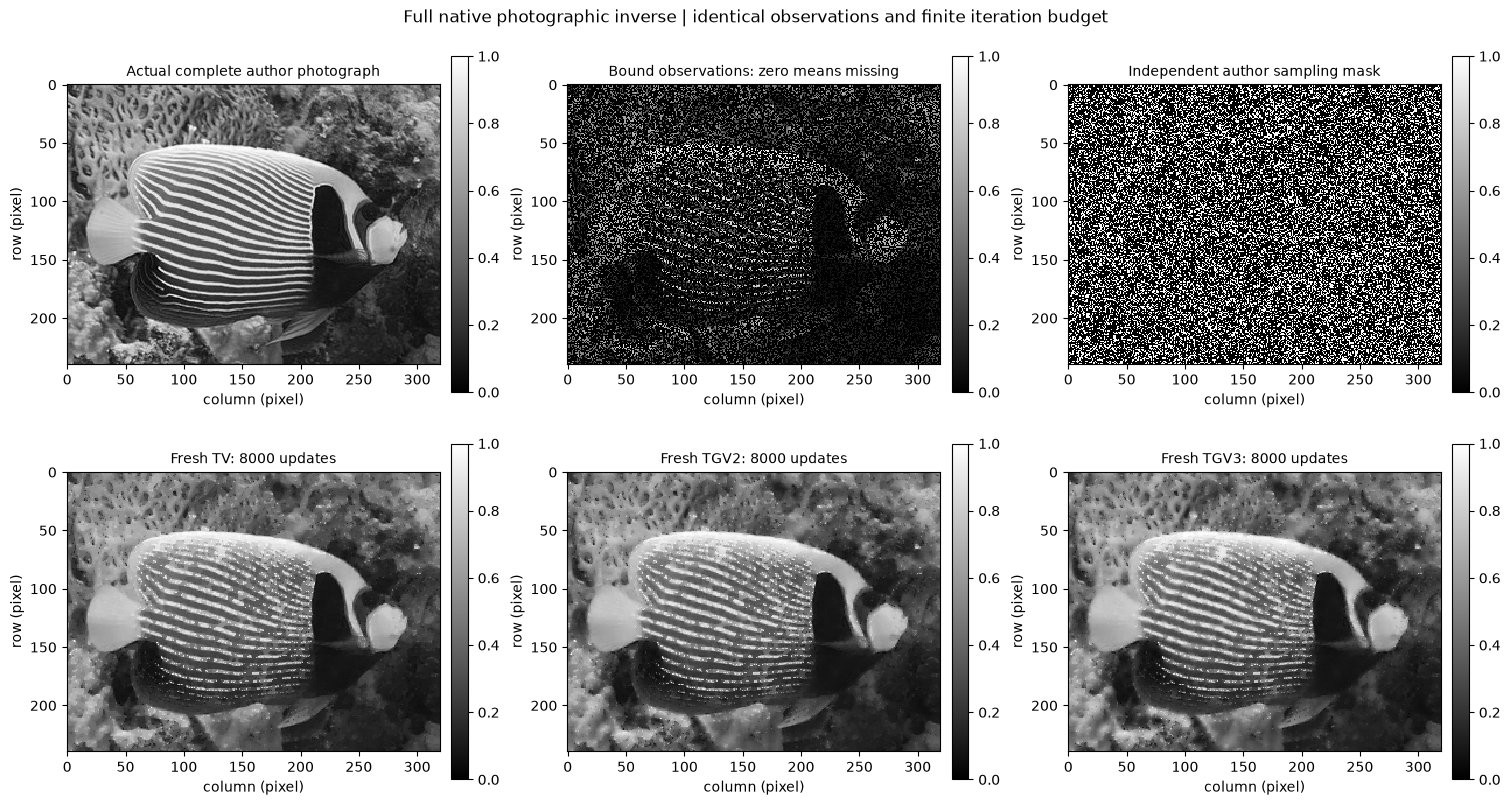

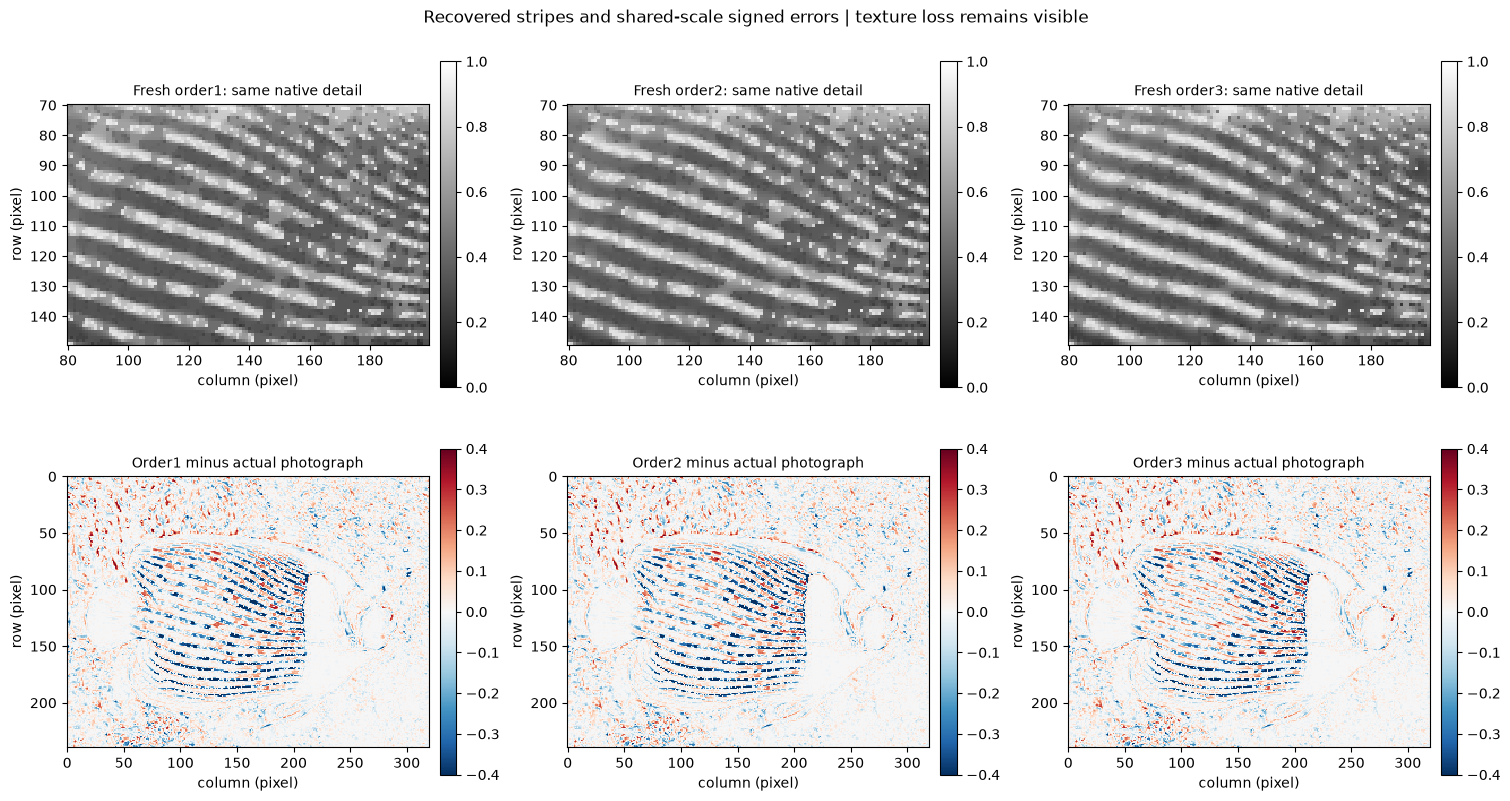

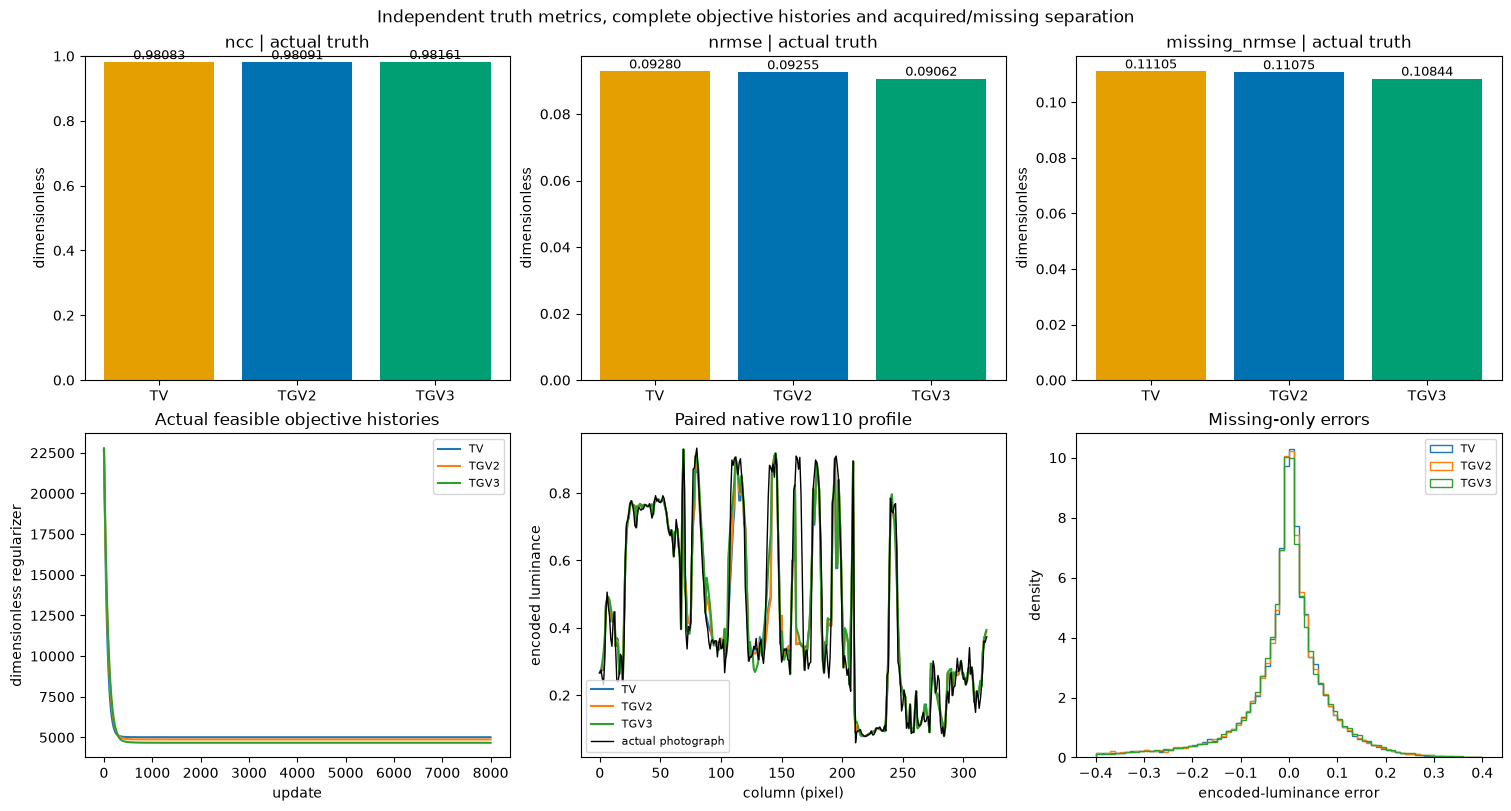

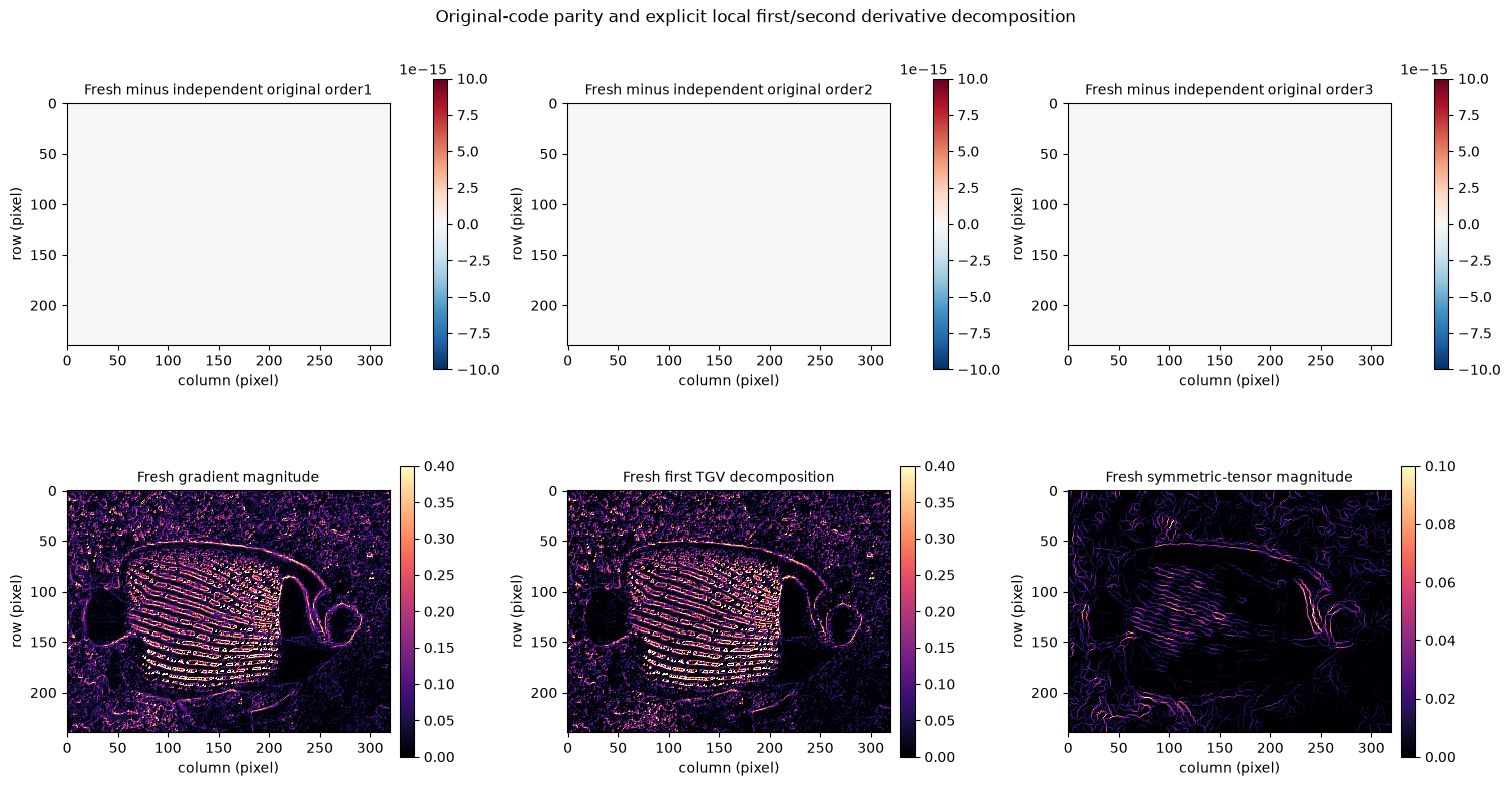

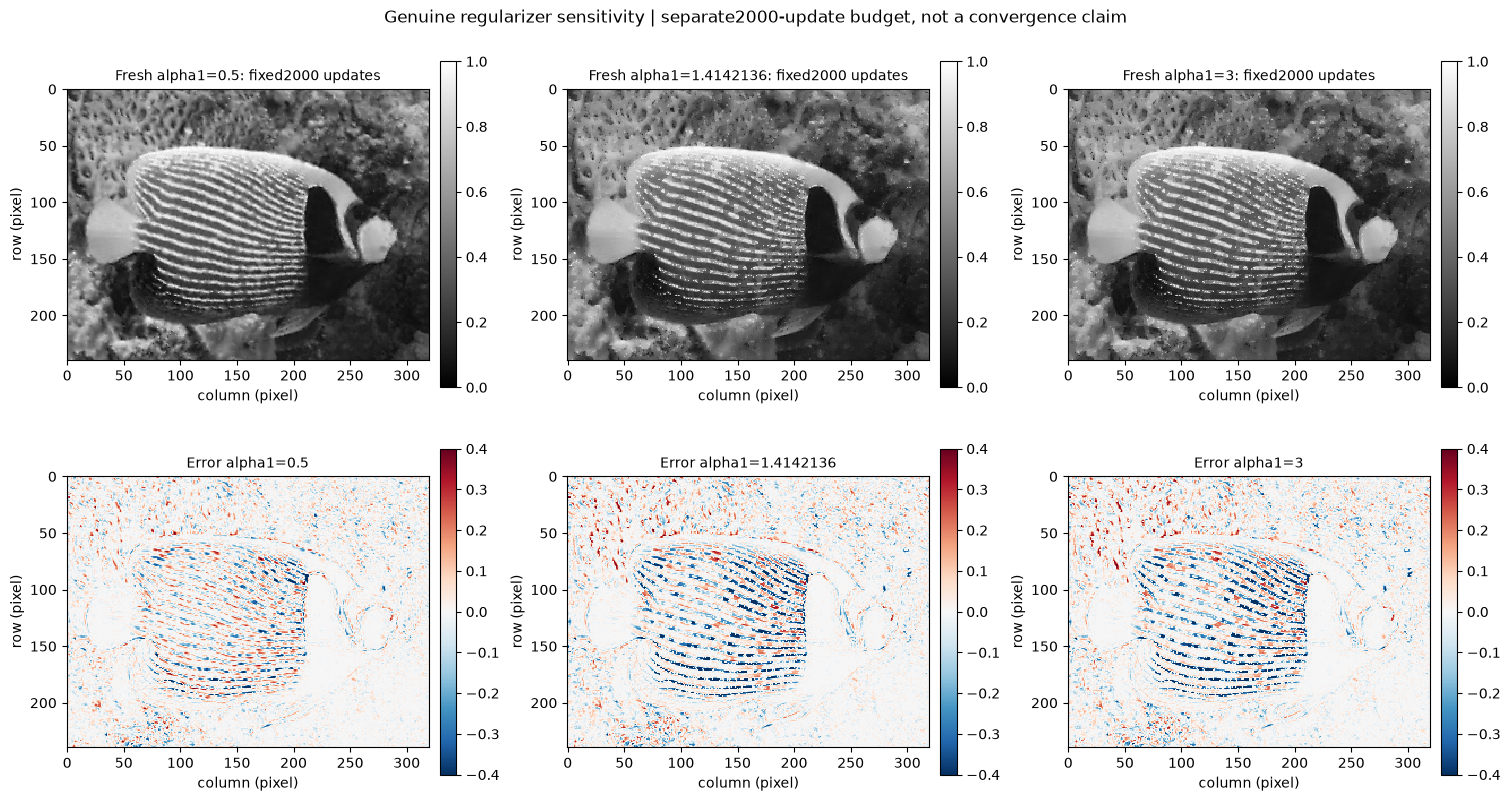

In [3]:
figures,numeric,metrics=make_figures(y,mask,truth,fresh,upstream)
metrics['fresh_runtime_seconds']=timings
export_dir=os.environ.get('IMAGING101_FIGURE_DIR')
if export_dir:
    export_figures(figures,numeric,metrics,export_dir)
print(json.dumps(metrics,indent=2))
for fig in figures:
    display(fig)
    plt.close(fig)


## 6. Conclusion

### Interpretation and limitations

All plotted methods above were computed during this execution. Original source results are separately identified numerical comparisons; historical paper PSNR/SSIM are not fresh measurements or the same metric definition. The actual photograph before masking is genuine truth for this synthetic sampling experiment. It is not an independent instrument recording of missing pixels.

TGV reconstructs smooth structure and many edges, but missing high-frequency stripes are not determined by the sparse observation and may remain blurred. Good global NCC can coexist with visibly lost detail, so missing-only error, shared-scale signed maps and native-coordinate profiles are retained. There is no radiance calibration, denoising claim or universal recovery guarantee. All four evaluation checks and independent operator/physics/parity tests have separate evidential roles.

The complete photograph supplies actual pixel truth for the synthetic mask experiment, not independent physical radiance. Missing-only error and stripe profiles assess detail that global NCC can obscure. The 8000-update standard and 2000-update sensitivity runs retain different finite budgets.
